In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df=pd.read_csv("/content/StudentsPerformance.csv")

In [3]:
df.head()

,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


In [4]:
df.shape

(1000, 8)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


In [6]:
df.isnull().sum()

,0
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.describe()

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [20]:
categorical_cols = [
    'gender',
    'race/ethnicity',
    'parental level of education',
    'lunch',
    'test preparation course'
]

for col in categorical_cols:
    df[col] = (
        df[col]
        .astype('string')
        .str.strip()
        .str.lower()
    )

# Check the cleaned categories
for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())


gender:
<StringArray>
['female', 'male']
Length: 2, dtype: string

race/ethnicity:
<StringArray>
['group b', 'group c', 'group a', 'group d', 'group e']
Length: 5, dtype: string

parental level of education:
<StringArray>
[ "bachelor's degree",       'some college',    "master's degree",
 "associate's degree",        'high school',   'some high school']
Length: 6, dtype: string

lunch:
<StringArray>
['standard', 'free/reduced']
Length: 2, dtype: string

test preparation course:
<StringArray>
['none', 'completed']
Length: 2, dtype: string


In [21]:
score_cols = [
    'math score',
    'reading score',
    'writing score'
]

# Calculate statistical measures
stats = df[score_cols].agg(
    ['mean', 'median', 'std']
).T

# Calculate quartiles
stats['Q1'] = df[score_cols].quantile(0.25)
stats['Q2'] = df[score_cols].quantile(0.50)
stats['Q3'] = df[score_cols].quantile(0.75)

print(stats.round(2))

                mean  median    std     Q1    Q2    Q3
math score     66.09    66.0  15.16  57.00  66.0  77.0
reading score  69.17    70.0  14.60  59.00  70.0  79.0
writing score  68.05    69.0  15.20  57.75  69.0  79.0


In [22]:
df['total marks'] = (
    df['math score']
    + df['reading score']
    + df['writing score']
)

df['percentage'] = (
    df['total marks'] / 300
) * 100

print(df[
    ['math score', 'reading score',
     'writing score', 'total marks', 'percentage']
].head())

print(df[['total marks', 'percentage']].describe())

   math score  reading score  writing score  total marks  percentage
0          72             72             74          218   72.666667
1          69             90             88          247   82.333333
2          90             95             93          278   92.666667
3          47             57             44          148   49.333333
4          76             78             75          229   76.333333
       total marks   percentage
count  1000.000000  1000.000000
mean    203.312000    67.770667
std      42.771978    14.257326
min      27.000000     9.000000
25%     175.000000    58.333333
50%     205.000000    68.333333
75%     233.000000    77.666667
max     300.000000   100.000000


In [23]:
subjects = ['math score', 'reading score', 'writing score']

print(df[subjects].describe())

print("Median:")
print(df[subjects].median())

       math score  reading score  writing score
count  1000.00000    1000.000000    1000.000000
mean     66.08900      69.169000      68.054000
std      15.16308      14.600192      15.195657
min       0.00000      17.000000      10.000000
25%      57.00000      59.000000      57.750000
50%      66.00000      70.000000      69.000000
75%      77.00000      79.000000      79.000000
max     100.00000     100.000000     100.000000
Median:
math score       66.0
reading score    70.0
writing score    69.0
dtype: float64


In [24]:
for col in subjects:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = df[(df[col] < lower) | (df[col] > upper)]

    print(col, "Outliers:", len(outliers))

df.to_csv("Student_Performance_Cleaned.csv", index=False)

print("Task completed!")

math score Outliers: 8
reading score Outliers: 6
writing score Outliers: 5
Task completed!


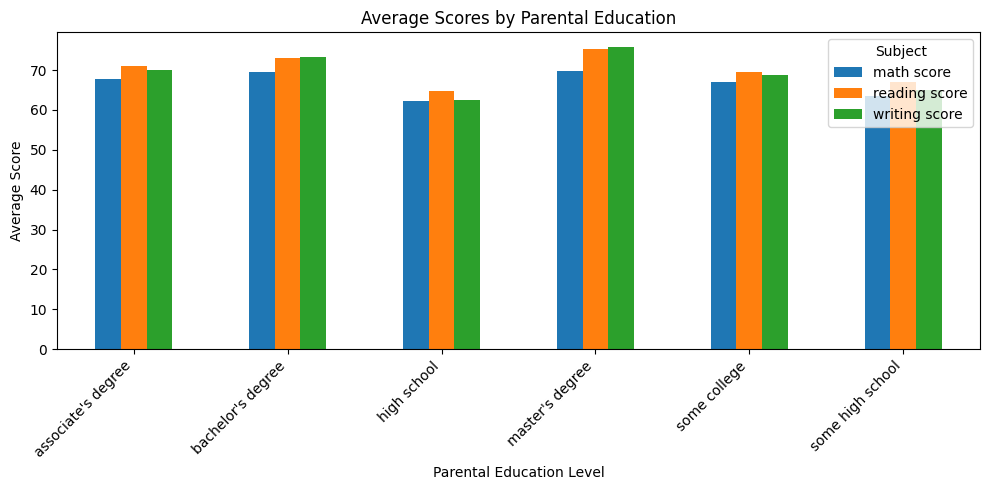

In [25]:
education_avg = df.groupby(
    'parental level of education'
)[subjects].mean()
education_avg.plot(kind='bar', figsize=(10, 5))
plt.title('Average Scores by Parental Education')
plt.xlabel('Parental Education Level')
plt.ylabel('Average Score')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Subject')
plt.tight_layout()
plt.show()

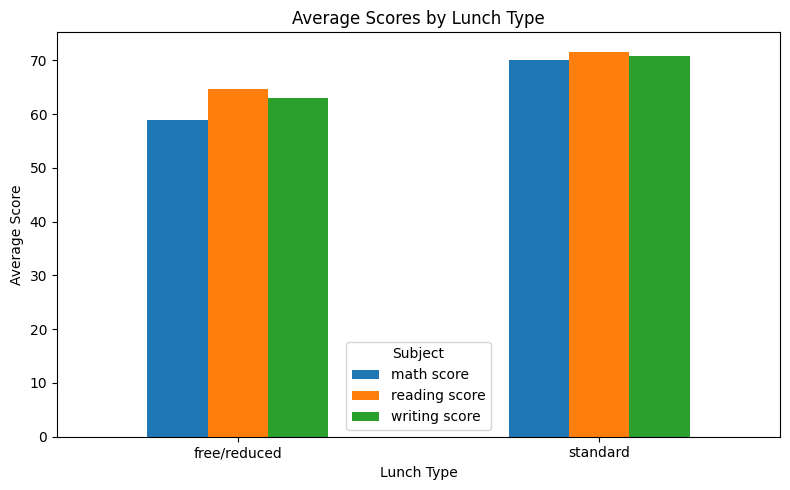

In [26]:
lunch_avg = df.groupby('lunch')[subjects].mean()

lunch_avg.plot(kind='bar', figsize=(8, 5))

plt.title('Average Scores by Lunch Type')
plt.xlabel('Lunch Type')
plt.ylabel('Average Score')
plt.xticks(rotation=0)
plt.legend(title='Subject')
plt.tight_layout()
plt.show()

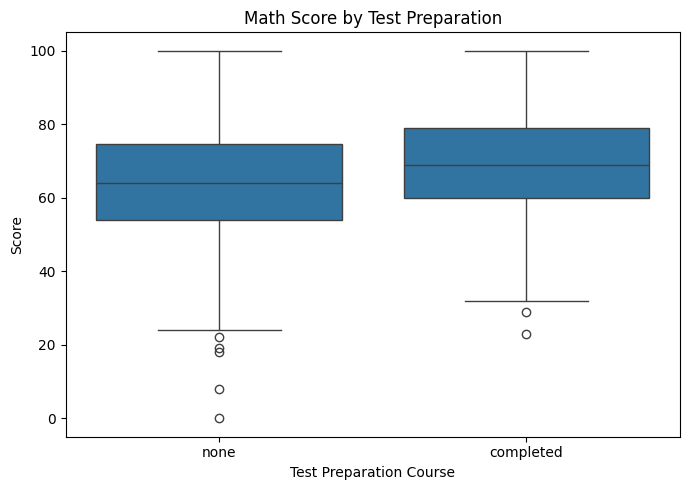

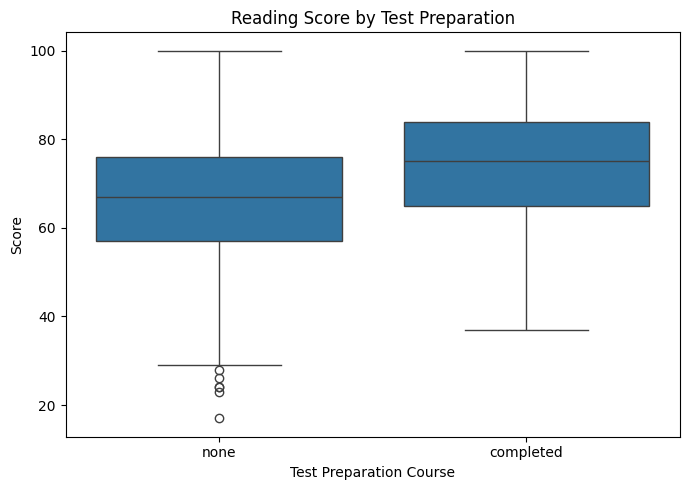

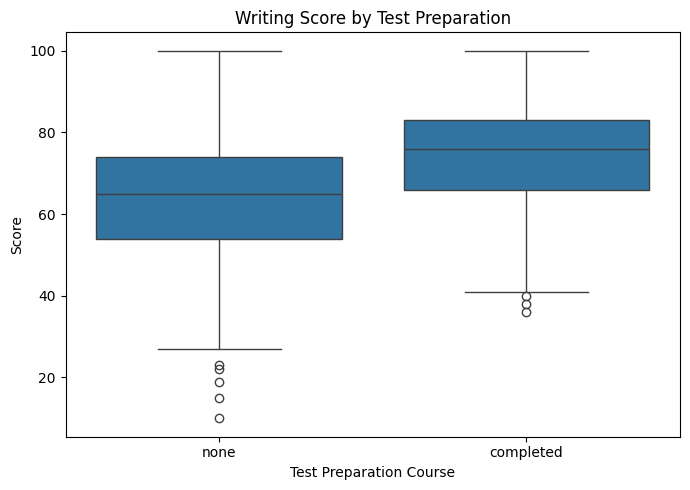

In [27]:
for subject in subjects:
    plt.figure(figsize=(7, 5))

    sns.boxplot(
        data=df,
        x='test preparation course',
        y=subject
    )

    plt.title(f'{subject.title()} by Test Preparation')
    plt.xlabel('Test Preparation Course')
    plt.ylabel('Score')
    plt.tight_layout()
    plt.show()

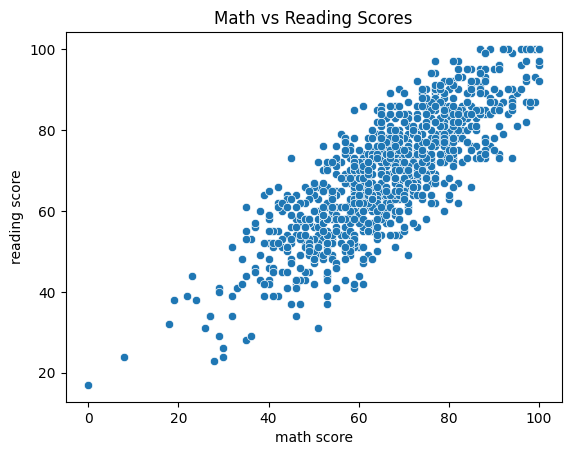

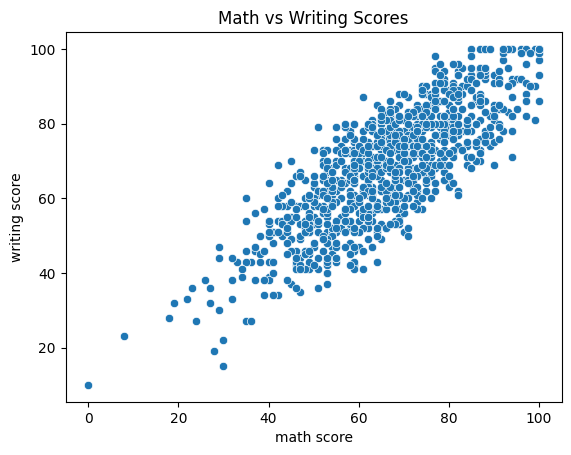

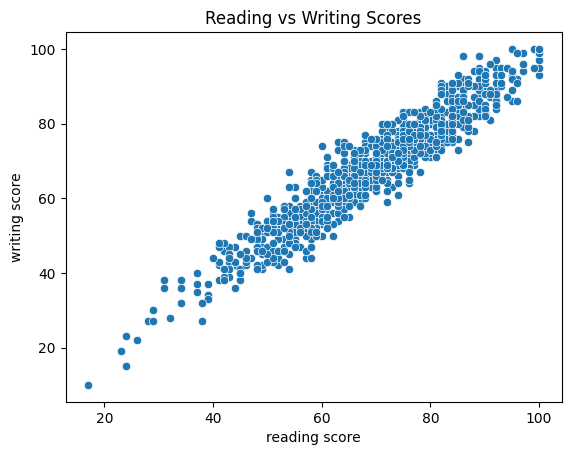

In [28]:
sns.scatterplot(data=df, x='math score', y='reading score')
plt.title('Math vs Reading Scores')
plt.show()

sns.scatterplot(data=df, x='math score', y='writing score')
plt.title('Math vs Writing Scores')
plt.show()

sns.scatterplot(data=df, x='reading score', y='writing score')
plt.title('Reading vs Writing Scores')
plt.show()

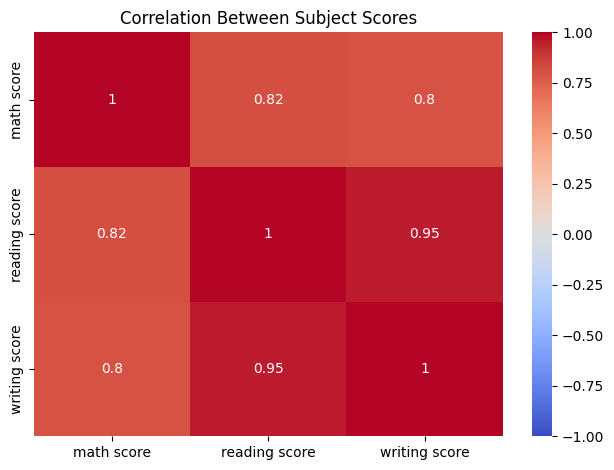

In [29]:
correlation = df[subjects].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    vmin=-1,
    vmax=1
)

plt.title('Correlation Between Subject Scores')
plt.tight_layout()
plt.show()